In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df = pd.read_csv('student_performance.csv')
df.head()

,Student_ID,Attendance_%,CGPA,Assignments_Submitted,Lab_Hours_Per_Week,Has_Part_Time_Job,Scholarship,Counsellor_Visits,Dropped_Out
0,STU0672,82.3,7.18,27,8.2,1,1,1,0
1,STU0275,60.0,5.92,29,16.2,0,0,1,1
2,STU1683,87.5,5.23,5,1.2,0,0,4,0
3,STU0663,81.4,6.44,23,10.0,1,0,1,0
4,STU0641,67.4,NaN,12,8.8,0,1,2,1


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2040 entries, 0 to 2039
Data columns (total 9 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Student_ID             2040 non-null   object 
 1   Attendance_%           1942 non-null   float64
 2   CGPA                   1940 non-null   float64
 3   Assignments_Submitted  2040 non-null   int64  
 4   Lab_Hours_Per_Week     2040 non-null   float64
 5   Has_Part_Time_Job      2040 non-null   object 
 6   Scholarship            2040 non-null   int64  
 7   Counsellor_Visits      2040 non-null   int64  
 8   Dropped_Out            2040 non-null   int64  
dtypes: float64(3), int64(4), object(2)
memory usage: 143.6+ KB


In [ ]:
df.columns

Index(['Student_ID', 'Attendance_%', 'CGPA', 'Assignments_Submitted',
       'Lab_Hours_Per_Week', 'Has_Part_Time_Job', 'Scholarship',
       'Counsellor_Visits', 'Dropped_Out'],
      dtype='object')

In [ ]:
df.describe()

,Attendance_%,CGPA,Assignments_Submitted,Lab_Hours_Per_Week,Scholarship,Counsellor_Visits,Dropped_Out
count,1942.000000,1940.000000,2040.000000,2040.000000,2040.000000,2040.000000,2040.000000
mean,72.217971,6.842371,14.828922,8.030392,0.307353,1.219118,0.358824
std,14.785443,1.344828,8.906998,3.001507,0.461510,1.280834,0.479773
min,20.000000,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,62.600000,5.970000,7.000000,6.000000,0.000000,0.000000,0.000000
50%,71.600000,6.800000,15.000000,8.000000,0.000000,1.000000,0.000000
75%,81.900000,7.602500,23.000000,10.100000,1.000000,2.000000,1.000000
max,113.800000,12.970000,30.000000,18.100000,1.000000,4.000000,1.000000


In [ ]:
df.isnull().sum()

,0
Student_ID,0
Attendance_%,98
CGPA,100
Assignments_Submitted,0
Lab_Hours_Per_Week,0
Has_Part_Time_Job,0
Scholarship,0
Counsellor_Visits,0
Dropped_Out,0


In [ ]:
df['Has_Part_Time_Job'] = df['Has_Part_Time_Job'].replace({'Yes': 1, 'No': 0})
df['Has_Part_Time_Job'] = pd.to_numeric(df['Has_Part_Time_Job'])

In [ ]:
df['Attendance_%'] = df['Attendance_%'].clip(upper=100)

In [ ]:
df.isnull().sum()

,0
Student_ID,0
Attendance_%,98
CGPA,100
Assignments_Submitted,0
Lab_Hours_Per_Week,0
Has_Part_Time_Job,0
Scholarship,0
Counsellor_Visits,0
Dropped_Out,0


In [ ]:
df['CGPA'] = df['CGPA'].clip(upper=10)

In [ ]:
df['Attendance_%'] = df['Attendance_%'].fillna(df['Attendance_%'].median())
df['CGPA'] = df['CGPA'].fillna(df['CGPA'].median())

In [ ]:
df.isnull().sum()

,0
Student_ID,0
Attendance_%,0
CGPA,0
Assignments_Submitted,0
Lab_Hours_Per_Week,0
Has_Part_Time_Job,0
Scholarship,0
Counsellor_Visits,0
Dropped_Out,0


## **Univariate Analysis**

Text(0.5, 1.0, 'Distribution of Student Attendance (%)')

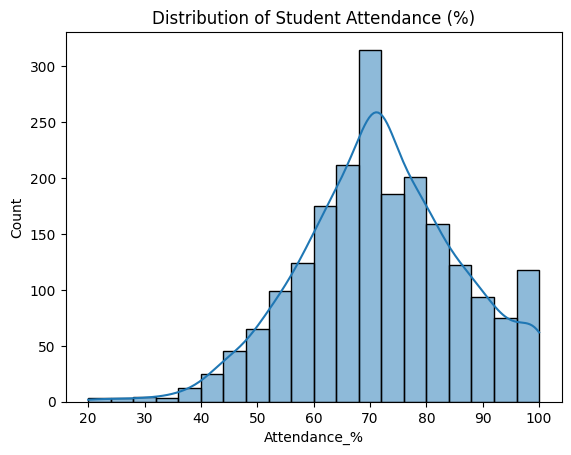

In [ ]:
fig, ax = plt.subplots()

sns.histplot(
    data=df,
    x='Attendance_%',
    bins=20,
    kde=True,
    ax=ax
)

ax.set_title('Distribution of Student Attendance (%)')

The distribution of student attendance is approximately normal, with most students clustered between 60% and 80%. A small proportion of students fall into the low attendance range (<50%), which may indicate a potential at-risk group. This suggests that while most students maintain moderate attendance, low attendance could be an early warning signal for dropout.

## **Bivariate Analysis**

Text(0.5, 1.0, 'Attendance vs CGPA')

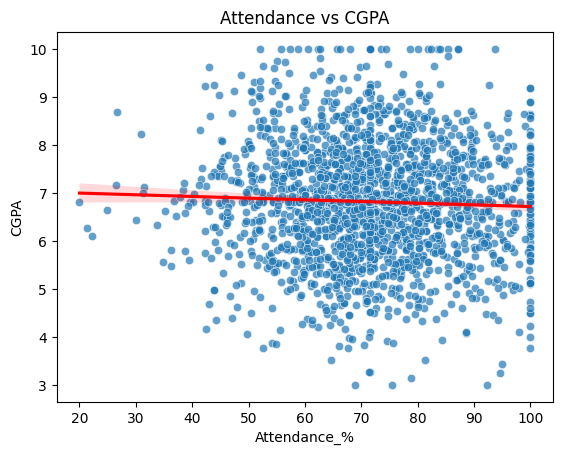

In [ ]:
fig, ax = plt.subplots()

sns.scatterplot(
    data=df,
    x='Attendance_%',
    y='CGPA',
    alpha=0.7,
    ax=ax
)

sns.regplot(
    data=df,
    x='Attendance_%',
    y='CGPA',
    scatter=False,
    color='red',
    ax=ax
)

ax.set_title('Attendance vs CGPA')

The relationship between attendance and CGPA appears weak, with a slight negative trend observed. This indicates that attendance alone is not a strong predictor of academic performance in this dataset. Students with similar attendance levels exhibit a wide range of CGPA values, suggesting that additional behavioral or academic factors play a significant role in determining performance.

## Multivariate **Analysis**

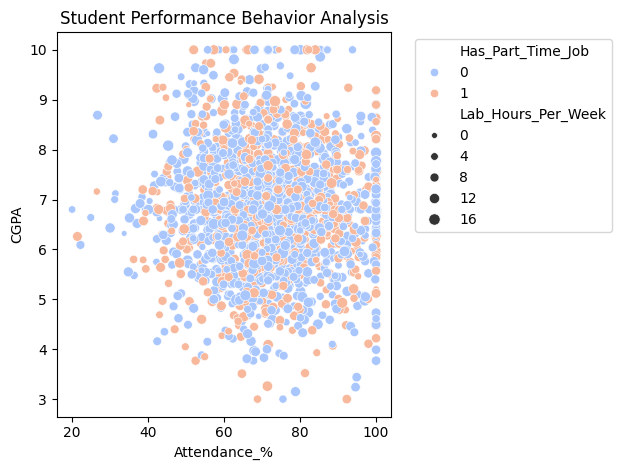

In [ ]:
fig, ax = plt.subplots()

sns.scatterplot(
    data=df,
    x='Attendance_%',
    y='CGPA',
    hue='Has_Part_Time_Job',
    size='Lab_Hours_Per_Week',
    palette='coolwarm',
    ax=ax
)

ax.set_title('Student Performance Behavior Analysis')

ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()

When analyzing attendance, CGPA, part-time job status, and lab hours together, it becomes evident that student performance is influenced by multiple interacting factors. Students with similar attendance levels show different academic outcomes depending on their lab engagement and whether they have part-time jobs. This highlights that dropout risk cannot be determined using a single variable, but rather a combination of academic and behavioral indicators.

## **Correlation Heatmap**

Text(0.5, 1.0, 'Correlation Between Features')

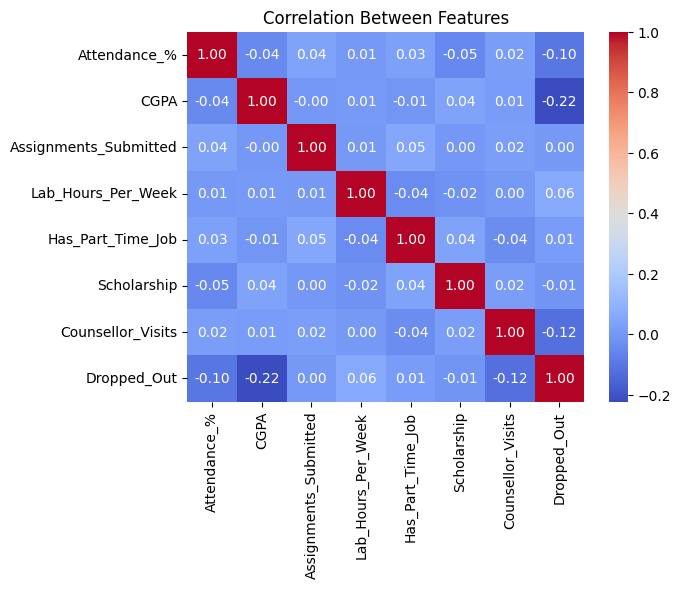

In [ ]:
fig, ax = plt.subplots()

corr = df.corr(numeric_only=True)

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    fmt=".2f",
    ax=ax
)

ax.set_title('Correlation Between Features')

The correlation matrix reveals that most features have weak individual correlations with dropout status, with CGPA showing the strongest negative correlation. Attendance and counsellor visits also show slight relationships, but no single feature dominates. This indicates that dropout prediction is a complex problem requiring a combination of multiple features rather than relying on a single strong predictor.

# **Model Training**

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix, classification_report
from sklearn.preprocessing import LabelEncoder

In [ ]:
X = df.drop(['Dropped_Out', 'Student_ID'], axis=1)
y = df['Dropped_Out']

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [ ]:
model = RandomForestClassifier(n_estimators=100, class_weight={0:1, 1:3}, random_state=42)
model.fit(X_train, y_train)

RandomForestClassifier(class_weight={0: 1, 1: 3}, random_state=42)

In [ ]:
y_pred = model.predict(X_test)
y_pred

array([0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 1, 1, 1,
       0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 1, 0, 0, 0, 0, 1, 0, 1, 1, 1, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0,
       1, 1, 0, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 1, 1,
       1, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0,
       1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0,
       1, 0, 1, 0, 1, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0,
       0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 1,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0,
       0, 1, 1, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0,
       0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0,

In [ ]:
y_prob = model.predict_proba(X_test)[:, 1]
y_prob

array([0.38, 0.34, 0.23, 0.43, 0.17, 0.21, 0.14, 0.15, 0.74, 0.07, 0.53,
       0.22, 0.13, 0.2 , 0.13, 0.86, 0.46, 0.27, 0.22, 0.75, 0.59, 0.56,
       0.22, 0.24, 0.4 , 0.27, 0.32, 0.25, 0.68, 0.26, 0.12, 0.04, 0.34,
       0.38, 0.7 , 0.09, 0.2 , 0.18, 0.17, 0.17, 0.25, 0.39, 0.28, 0.24,
       0.32, 0.22, 0.39, 0.26, 0.2 , 0.13, 0.75, 0.58, 0.75, 0.19, 0.4 ,
       0.19, 0.3 , 0.36, 0.13, 0.33, 0.16, 0.12, 0.4 , 0.12, 0.13, 0.24,
       0.31, 0.25, 0.61, 0.32, 0.27, 0.2 , 0.43, 0.66, 0.21, 0.78, 0.71,
       0.78, 0.54, 0.57, 0.36, 0.67, 0.2 , 0.13, 0.15, 0.29, 0.17, 0.07,
       0.54, 0.6 , 0.44, 0.79, 0.58, 0.16, 0.89, 0.32, 0.11, 0.43, 0.19,
       0.11, 0.11, 0.25, 0.82, 0.25, 0.38, 0.7 , 0.31, 0.13, 0.52, 0.56,
       0.54, 0.15, 0.19, 0.25, 0.5 , 0.76, 0.82, 0.75, 0.29, 0.23, 0.4 ,
       0.77, 0.24, 0.31, 0.23, 0.44, 0.57, 0.18, 0.14, 0.33, 0.58, 0.27,
       0.67, 0.81, 0.78, 0.19, 0.24, 0.23, 0.23, 0.31, 0.1 , 0.38, 0.32,
       0.22, 0.18, 0.07, 0.15, 0.17, 0.22, 0.28, 0.

In [ ]:
print("Accuracy :", round(accuracy_score(y_test, y_pred), 3))
print("Precision:", round(precision_score(y_test, y_pred), 3))
print("Recall   :", round(recall_score(y_test, y_pred), 3))

Accuracy : 0.74
Precision: 0.717
Recall   : 0.452


In [ ]:
risk_level = pd.cut(y_prob,bins=[0, 0.3, 0.6, 1],labels=['Safe', 'At Risk', 'Critical'])

In [ ]:
risk_level

['At Risk', 'At Risk', 'Safe', 'At Risk', 'Safe', ..., 'At Risk', 'At Risk', 'At Risk', 'Safe', 'Safe']
Length: 408
Categories (3, object): ['Safe' < 'At Risk' < 'Critical']

In [ ]:
output = X_test.copy()
output['Actual'] = y_test.values
output['Risk_Score'] = y_prob
output['Risk_Level'] = risk_level

In [ ]:
output

,Attendance_%,CGPA,Assignments_Submitted,Lab_Hours_Per_Week,Has_Part_Time_Job,Scholarship,Counsellor_Visits,Actual,Risk_Score,Risk_Level
987,72.2,7.20,28,6.9,0,0,2,1,0.38,At Risk
1727,64.7,6.85,12,15.9,0,0,1,1,0.34,At Risk
359,59.7,6.95,14,6.3,0,0,2,0,0.23,Safe
367,65.1,6.47,13,12.0,1,0,0,0,0.43,At Risk
903,68.5,5.97,11,5.9,1,0,1,0,0.17,Safe
...,...,...,...,...,...,...,...,...,...,...
1195,59.4,7.06,22,6.9,1,1,0,0,0.60,At Risk
379,88.9,6.68,21,14.0,1,0,1,1,0.36,At Risk
1983,61.3,6.15,8,9.3,1,1,2,0,0.32,At Risk
1953,62.7,7.32,1,3.2,1,0,2,0,0.16,Safe


In [ ]:
top_10 = output.sort_values(by='Risk_Score', ascending=False).head(10)
top_10

,Attendance_%,CGPA,Assignments_Submitted,Lab_Hours_Per_Week,Has_Part_Time_Job,Scholarship,Counsellor_Visits,Actual,Risk_Score,Risk_Level
1752,72.3,5.63,12,6.2,1,0,0,1,0.97,Critical
1849,58.1,6.26,8,8.9,1,0,0,1,0.90,Critical
491,77.3,5.62,27,8.5,0,0,0,1,0.89,Critical
1090,74.3,5.28,9,4.3,1,1,0,1,0.88,Critical
212,67.3,5.84,5,7.3,1,0,0,1,0.86,Critical
608,53.7,5.47,18,12.0,0,0,0,1,0.86,Critical
1890,43.3,5.64,3,10.7,1,0,4,1,0.86,Critical
1450,47.0,4.40,3,7.5,1,1,0,1,0.85,Critical
916,64.6,5.58,8,2.8,1,0,0,0,0.84,Critical
307,61.0,5.78,27,13.2,0,0,0,1,0.84,Critical


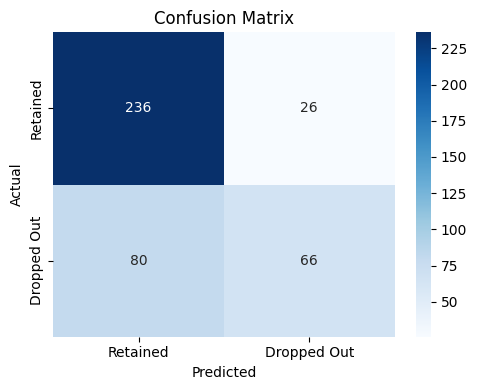

In [ ]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Retained', 'Dropped Out'],
            yticklabels=['Retained', 'Dropped Out'])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()

In [ ]:
feature_importance = pd.Series(
    model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

feature_importance

,0
CGPA,0.281188
Attendance_%,0.227245
Lab_Hours_Per_Week,0.200130
Assignments_Submitted,0.161981
Counsellor_Visits,0.082579
Has_Part_Time_Job,0.023497
Scholarship,0.023380


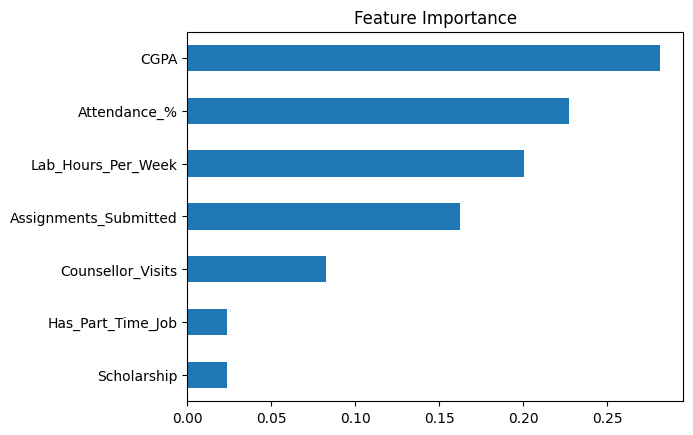

In [ ]:
import matplotlib.pyplot as plt

feature_importance.sort_values().plot(kind='barh')
plt.title('Feature Importance')
plt.show()

## **Input Form**

In [ ]:
attendance = float(input("Enter Attendance (%): "))
cgpa = float(input("Enter CGPA: "))
assignments = int(input("Assignments Submitted: "))
lab_hours = float(input("Lab Hours per Week: "))
job = int(input("Has Part-Time Job (0/1): "))
scholarship = int(input("Scholarship (0/1): "))
counsellor = int(input("Counsellor Visits: "))

input_data = pd.DataFrame([{
    'Attendance_%': attendance,
    'CGPA': cgpa,
    'Assignments_Submitted': assignments,
    'Lab_Hours_Per_Week': lab_hours,
    'Has_Part_Time_Job': job,
    'Scholarship': scholarship,
    'Counsellor_Visits': counsellor
}])

risk_score = model.predict_proba(input_data)[:, 1]

risk_level = pd.cut(
    risk_score,
    bins=[0, 0.3, 0.6, 1],
    labels=['Safe', 'At Risk', 'Critical']
)

print("Risk Score:", risk_score[0])
print("Risk Level:", risk_level[0])

Enter Attendance (%): 40
Enter CGPA: 5
Assignments Submitted: 8
Lab Hours per Week: 7
Has Part-Time Job (0/1): 1
Scholarship (0/1): 0
Counsellor Visits: 0
Risk Score: 0.61
Risk Level: Critical


In [ ]:
y.value_counts()

,count
Dropped_Out,
0,1308
1,732


In [ ]:
import pickle

pickle.dump(model, open('model.pkl', 'wb'))